## Instalando librerías

%pip install pandas sodapy

In [2]:
import pandas as pd
from sodapy import Socrata

In [7]:
import time

TOKEN = None
client = Socrata("www.datos.gov.co", TOKEN, timeout=300)

DATASET = "7y2j-43cv"

columnas = (
    "pk, matricula, fecha_radica_texto, fecha_apertura_texto, year_radica, orip, "
    "divipola, departamento, municipio, tipo_predio_zona, categoria_ruralidad_2024, "
    "num_anotacion, estado_folio, folios_derivados, dinamica_2024, cod_natujur, "
    "nombre_natujur, numero_catastral, numero_catastral_antiguo, "
    "documento_justificativo, count_a, count_de, predios_nuevos, tiene_valor, "
    "tiene_mas_de_un_valor, valor"
)

filtro = "upper(departamento) = 'RISARALDA' AND upper(municipio) = 'PEREIRA'"

# --- 1. Cuántas filas hay ---
total = int(client.get(DATASET, select="count(*)", where=filtro)[0]["count"])
print(f"Filas a descargar: {total:,}")

# --- 2. Descarga por páginas con reintentos ---
PAGINA = 10000
filas = []
offset = 0

while offset < total:
    for intento in range(5):
        try:
            bloque = client.get(
                DATASET,
                select=columnas,
                where=filtro,
                order="pk",          # orden estable para que la paginación no repita ni salte filas
                limit=PAGINA,
                offset=offset,
            )
            break
        except Exception as e:
            print(f"Error en offset {offset} (intento {intento + 1}/5): {e}")
            time.sleep(5 * (intento + 1))
    else:
        raise RuntimeError(f"No se pudo descargar el bloque desde offset {offset}")

    if not bloque:
        break
    filas.extend(bloque)
    offset += PAGINA
    print(f"Descargadas {len(filas):,} / {total:,}")

df = pd.DataFrame.from_records(filas)
print(df.shape)

# --- 3. Conversión de tipos ---
for col in ["year_radica", "num_anotacion", "count_a", "count_de", "valor"]:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors="coerce")

for col in ["fecha_radica_texto", "fecha_apertura_texto"]:
    if col in df.columns:
        df[col] = pd.to_datetime(df[col], errors="coerce")

# --- 4. Guardar para no repetir la descarga ---
df.to_csv("pereira.csv", index=False, sep=";", encoding="utf-8-sig")

df.head()

Filas a descargar: 552,153
Descargadas 10,000 / 552,153
Descargadas 20,000 / 552,153
Descargadas 30,000 / 552,153
Descargadas 40,000 / 552,153
Descargadas 50,000 / 552,153
Descargadas 60,000 / 552,153
Descargadas 70,000 / 552,153
Descargadas 80,000 / 552,153
Descargadas 90,000 / 552,153
Descargadas 100,000 / 552,153
Descargadas 110,000 / 552,153
Descargadas 120,000 / 552,153
Descargadas 130,000 / 552,153
Descargadas 140,000 / 552,153
Descargadas 150,000 / 552,153
Descargadas 160,000 / 552,153
Descargadas 170,000 / 552,153
Descargadas 180,000 / 552,153
Descargadas 190,000 / 552,153
Descargadas 200,000 / 552,153
Descargadas 210,000 / 552,153
Descargadas 220,000 / 552,153
Descargadas 230,000 / 552,153
Descargadas 240,000 / 552,153
Descargadas 250,000 / 552,153
Descargadas 260,000 / 552,153
Descargadas 270,000 / 552,153
Descargadas 280,000 / 552,153
Descargadas 290,000 / 552,153
Descargadas 300,000 / 552,153
Descargadas 310,000 / 552,153
Descargadas 320,000 / 552,153
Descargadas 330,000 / 

,pk,matricula,fecha_radica_texto,year_radica,orip,divipola,departamento,municipio,tipo_predio_zona,categoria_ruralidad_2024,...,nombre_natujur,documento_justificativo,count_a,count_de,predios_nuevos,tiene_valor,tiene_mas_de_un_valor,valor,fecha_apertura_texto,folios_derivados
0,66001-290-000005-00006-00307-2016,290-5,2016-09-06,2016,290,66001,RISARALDA,PEREIRA,URBANO,Ciudades y aglomeraciones,...,COMPRAVENTA DERECHOS DE CUOTA,00-ESCRITURA 1789 DE 25/08/2016; NOTARIA SEXT...,1,2,0,1,0,0.0,NaT,NaN
1,66001-290-000005-00007-00307-2021,290-5,NaT,2021,290,66001,RISARALDA,PEREIRA,URBANO,Ciudades y aglomeraciones,...,COMPRAVENTA DERECHOS DE CUOTA,00-ESCRITURA 1768 DEL 18/08/21; PEREIRA,1,1,0,1,0,33000000.0,1974-05-03,NaN
2,66001-290-000006-00015-00842-2016,290-6,2016-11-22,2016,290,66001,RISARALDA,PEREIRA,URBANO,Ciudades y aglomeraciones,...,CANCELACIÓN PROVIDENCIA ADMINISTRATIVA,00-OFICIO 3187 DE 15/11/2016; ALCALDIA DE PER...,1,1,0,1,0,0.0,NaT,NaN
3,66001-290-000006-00016-00109-2016,290-6,2016-12-02,2016,290,66001,RISARALDA,PEREIRA,URBANO,Ciudades y aglomeraciones,...,ADJUDICACIÓN EN SUCESION,00-ESCRITURA 5308 DE 15/11/2016; NOTARIA CUAR...,8,1,0,1,0,378200000.0,NaT,NaN
4,66001-290-000006-00017-00301-2022,290-6,NaT,2022,290,66001,RISARALDA,PEREIRA,URBANO,Ciudades y aglomeraciones,...,ADJUDICACIÓN SUCESIÓN DERECHO DE CUOTA,00-ESCRITURA 6648 DEL 21/12/21; PEREIRA,3,1,0,1,0,18000000.0,1974-05-02,NaN


In [8]:
import pandas as pd

def perfil(df, max_cat=8):
    print("SHAPE:", df.shape)
    print("\nDTYPES + NULOS + ÚNICOS")
    resumen = pd.DataFrame({
        "dtype": df.dtypes.astype(str),
        "nulos_%": (df.isna().mean() * 100).round(2),
        "unicos": df.nunique(),
    })
    print(resumen.to_string())

    print("\nNUMÉRICAS")
    num = df.select_dtypes("number")
    if not num.empty:
        print(num.describe(percentiles=[.01, .25, .5, .75, .99]).T.round(2).to_string())

    print("\nFECHAS (min / max)")
    for c in df.select_dtypes("datetime"):
        print(c, df[c].min(), df[c].max())

    print("\nCATEGÓRICAS (top valores)")
    for c in df.select_dtypes("object"):
        if df[c].nunique() <= 50:
            print(f"\n{c}:")
            print(df[c].value_counts(dropna=False).head(max_cat).to_string())

    print("\nDUPLICADOS (filas completas):", df.duplicated().sum())
    if "pk" in df.columns:
        print("DUPLICADOS por pk:", df["pk"].duplicated().sum())

perfil(df)

SHAPE: (552153, 24)

DTYPES + NULOS + ÚNICOS
                                   dtype  nulos_%  unicos
pk                                object     0.00  552153
matricula                         object     0.00  142665
fecha_radica_texto        datetime64[ns]    78.63    1840
year_radica                        int64     0.00       9
orip                              object     0.00       1
divipola                          object     0.00       1
departamento                      object     0.00       1
municipio                         object     0.00       1
tipo_predio_zona                  object     0.00       3
categoria_ruralidad_2024          object     0.00       1
num_anotacion                      int64     0.00     579
estado_folio                      object     0.00       2
dinamica_2024                     object     0.00       2
cod_natujur                       object     0.00     296
nombre_natujur                    object     0.00     294
documento_justificativo    

In [9]:
print(df.sample(5, random_state=1).T.to_string())

                                                                                                                     400771                                        548185                                   505103                                   486755                                                      405516
pk                                                                                        66001-290-221595-00001-00363-2016             66001-290-251421-00007-00960-2023        66001-290-241226-00006-00219-2022        66001-290-238277-00001-00219-2020                           66001-290-222566-00005-00125-2019
matricula                                                                                                        290-221595                                    290-251421                               290-241226                               290-238277                                                  290-222566
fecha_radica_texto                                              

In [10]:
df.sample(200, random_state=1).to_csv("muestra.csv", index=False, sep=";", encoding="utf-8-sig")

---
---

In [11]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.options.display.float_format = "{:,.2f}".format

df = pd.read_csv("pereira.csv", sep=";", encoding="utf-8-sig", dtype={"pk": str, "matricula": str})

# Columnas constantes
constantes = [c for c in df.columns if df[c].nunique(dropna=False) == 1]
print("Se eliminan (constantes):", constantes)
df = df.drop(columns=constantes)

# Fechas
df["fecha_radica_texto"] = pd.to_datetime(df["fecha_radica_texto"], errors="coerce")
df["fecha_apertura_texto"] = pd.to_datetime(df["fecha_apertura_texto"], errors="coerce")
df.loc[df["fecha_apertura_texto"] < "1900-01-01", "fecha_apertura_texto"] = pd.NaT  # centinela 1899

# Variables derivadas de documento_justificativo
pat = re.compile(r"^\s*\d+-([A-ZÁÉÍÓÚÑ ]+?)\s+([\d\.\-A-Z]+)\s+(?:DE|DEL)\s+(\d{1,2}/\d{1,2}/\d{2,4})\s*;\s*(.*)$")

def parsear(txt):
    m = pat.match(str(txt))
    if not m:
        return pd.Series([None, None, None, None])
    tipo, num, fecha, ent = m.groups()
    d, mth, y = fecha.split("/")
    if len(y) == 2:
        y = "20" + y
    return pd.Series([tipo.strip(), num, pd.to_datetime(f"{d}/{mth}/{y}", format="%d/%m/%Y", errors="coerce"), ent.strip()])

df[["doc_tipo", "doc_numero", "doc_fecha", "doc_entidad"]] = df["documento_justificativo"].apply(parsear)
df["doc_fecha"] = pd.to_datetime(df["doc_fecha"], errors="coerce")

# Rezago entre fecha del documento y año de radicación
df["rezago_anios"] = df["year_radica"] - df["doc_fecha"].dt.year

# Valor
df["valor_pos"] = df["valor"].where(df["valor"] > 0)
df["log_valor"] = np.log10(df["valor_pos"])

print(df.shape)
print("Documentos parseados:", f"{df['doc_tipo'].notna().mean():.1%}")
df.head()

C:\Users\Felipe\AppData\Local\Temp\ipykernel_39104\4214750370.py:10: DtypeWarning: Columns (23) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv("pereira.csv", sep=";", encoding="utf-8-sig", dtype={"pk": str, "matricula": str})


Se eliminan (constantes): ['orip', 'divipola', 'departamento', 'municipio', 'categoria_ruralidad_2024', 'tiene_valor']
(552153, 25)
Documentos parseados: 99.7%


,pk,matricula,fecha_radica_texto,year_radica,tipo_predio_zona,num_anotacion,estado_folio,dinamica_2024,cod_natujur,nombre_natujur,...,valor,fecha_apertura_texto,folios_derivados,doc_tipo,doc_numero,doc_fecha,doc_entidad,rezago_anios,valor_pos,log_valor
0,66001-290-000005-00006-00307-2016,290-5,2016-09-06,2016,URBANO,6,ACTIVO,1,307,COMPRAVENTA DERECHOS DE CUOTA,...,0.00,NaT,NaN,ESCRITURA,1789,2016-08-25,NOTARIA SEXTA - PEREIRA,0.00,NaN,NaN
1,66001-290-000005-00007-00307-2021,290-5,NaT,2021,URBANO,7,ACTIVO,1,307,COMPRAVENTA DERECHOS DE CUOTA,...,"33,000,000.00",1974-05-03,NaN,ESCRITURA,1768,2021-08-18,PEREIRA,0.00,"33,000,000.00",7.52
2,66001-290-000006-00015-00842-2016,290-6,2016-11-22,2016,URBANO,15,ACTIVO,0,842,CANCELACIÓN PROVIDENCIA ADMINISTRATIVA,...,0.00,NaT,NaN,OFICIO,3187,2016-11-15,ALCALDIA DE PEREIRA - PEREIRA,0.00,NaN,NaN
3,66001-290-000006-00016-00109-2016,290-6,2016-12-02,2016,URBANO,16,ACTIVO,1,109,ADJUDICACIÓN EN SUCESION,...,"378,200,000.00",NaT,NaN,ESCRITURA,5308,2016-11-15,NOTARIA CUARTA - PEREIRA,0.00,"378,200,000.00",8.58
4,66001-290-000006-00017-00301-2022,290-6,NaT,2022,URBANO,17,ACTIVO,1,301,ADJUDICACIÓN SUCESIÓN DERECHO DE CUOTA,...,"18,000,000.00",1974-05-02,NaN,ESCRITURA,6648,2021-12-21,PEREIRA,1.00,"18,000,000.00",7.26


## Calidad de los datos


In [12]:
print("NULOS %")
print((df.isna().mean() * 100).round(2).sort_values(ascending=False).head(10))

print("\nDocumentos sin parsear (revisar patrón):")
print(df.loc[df["doc_tipo"].isna(), "documento_justificativo"].head(10).to_string())

print("\nFechas inconsistentes")
print("doc_fecha posterior a la radicación:", (df["doc_fecha"].dt.year > df["year_radica"]).sum())
print("rezago > 5 años:", (df["rezago_anios"] > 5).sum())

print("\nAnotaciones por folio")
por_folio = df.groupby("matricula").size()
print(por_folio.describe(percentiles=[.5, .9, .99]))
print("Folios con más de 50 anotaciones:", (por_folio > 50).sum())

print("\nInconsistencia estado/dinamica")
print(pd.crosstab(df["estado_folio"], df["dinamica_2024"], normalize="index").round(3))

NULOS %
folios_derivados       99.40
fecha_apertura_texto   95.58
fecha_radica_texto     78.63
valor_pos              62.62
log_valor              62.62
doc_fecha               0.30
doc_numero              0.30
rezago_anios            0.30
doc_tipo                0.30
doc_entidad             0.30
dtype: float64

Documentos sin parsear (revisar patrón):
90           00-RESOLUCION S/N DE 11/12/2023; 290-PEREIRA
190     00-OFICIO 07/1338 DE 16/12/2020;  JUZGADO SEPT...
271     00-OFICIO MMMP/2116 DE 03/12/2015;  ALCALDIA D...
438                        00-AUTO  DEL 04/02/21; PEREIRA
451     00-OFICIO 44 EAA DE 03/08/2016;  ALCALDIA DE P...
977           00-SENTENCIA S/N DE 25/10/2022; 290-PEREIRA
978           00-SENTENCIA S/N DE 25/05/2023; 290-PEREIRA
1546    00-OFICIO 35 EAA DE 03/08/2016;  ALCALDIA DE P...
1651          00-SENTENCIA S/N DE 25/10/2022; 290-PEREIRA
1688    00-OFICIO MMMP/11 DE 09/02/2015;  ALCALDIA DE ...

Fechas inconsistentes
doc_fecha posterior a la radicación: 108
r

## Temporalidad y tipo de predio

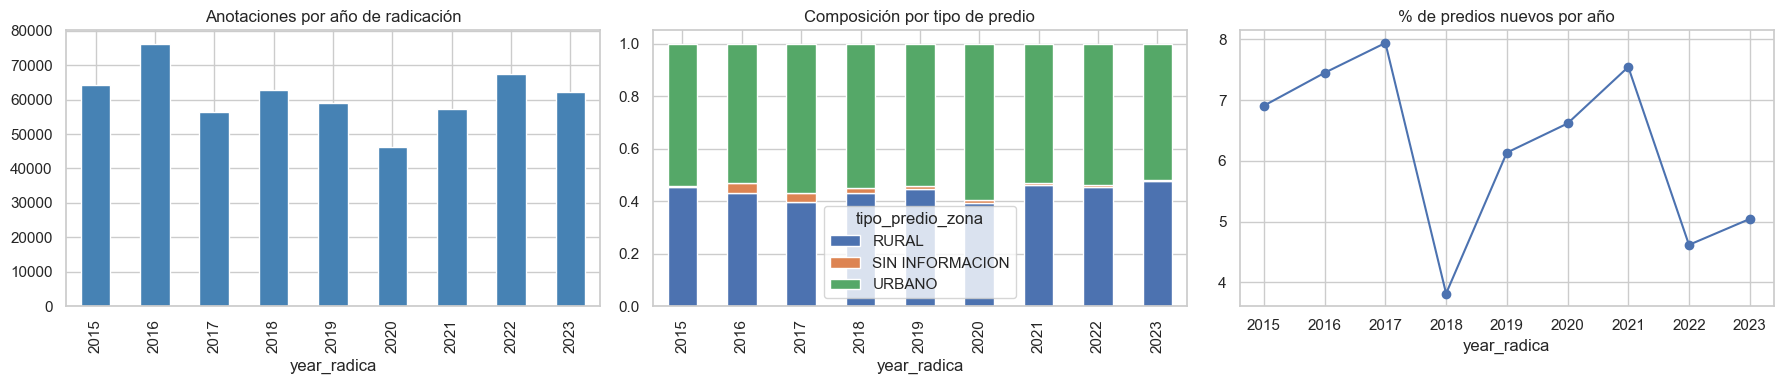

             anotaciones  folios  pct_con_valor  mediana_valor
year_radica                                                   
2015               64317   32258          34.16  43,007,500.00
2016               76309   35813          36.44  44,607,504.00
2017               56313   30695          40.05  48,000,000.00
2018               62916   31691          34.87  48,261,848.00
2019               59072   31560          36.15  51,000,000.00
2020               46303   26236          38.46  52,289,000.00
2021               57196   32193          41.34  60,000,000.00
2022               67397   32570          38.60  67,435,220.00
2023               62330   30672          37.37  60,000,000.00


In [13]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4))

df.groupby("year_radica").size().plot(kind="bar", ax=axes[0], color="steelblue")
axes[0].set_title("Anotaciones por año de radicación")

pd.crosstab(df["year_radica"], df["tipo_predio_zona"], normalize="index").plot(
    kind="bar", stacked=True, ax=axes[1])
axes[1].set_title("Composición por tipo de predio")

df.groupby("year_radica")["predios_nuevos"].mean().mul(100).plot(marker="o", ax=axes[2])
axes[2].set_title("% de predios nuevos por año")
plt.tight_layout()
plt.show()

print(df.groupby("year_radica").agg(
    anotaciones=("pk", "size"),
    folios=("matricula", "nunique"),
    pct_con_valor=("valor_pos", lambda s: s.notna().mean() * 100),
    mediana_valor=("valor_pos", "median"),
))

## Naturaleza jurídica

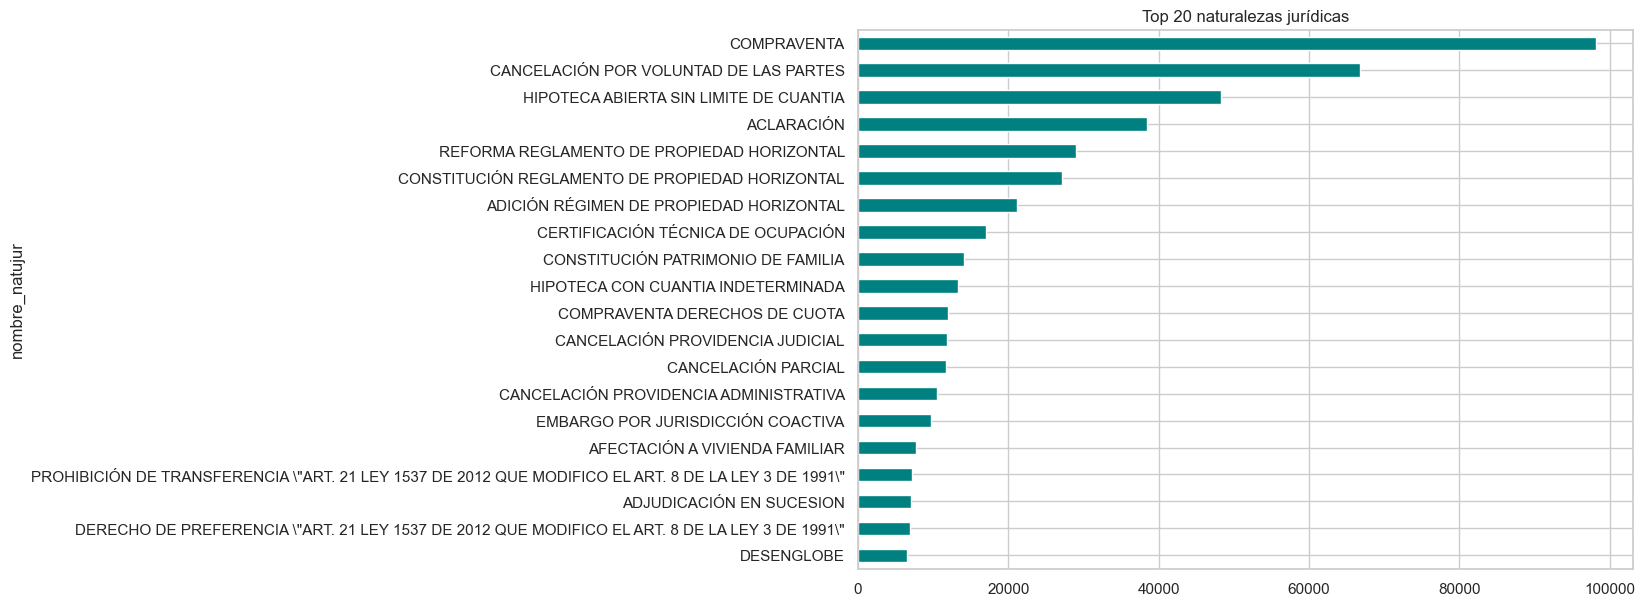

Concentración top 10: 67.7%


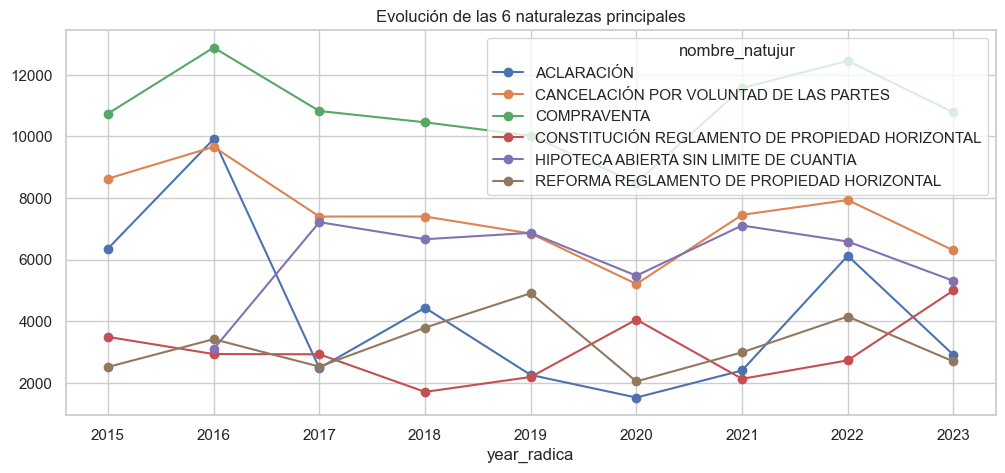

doc_tipo
ESCRITURA                   87.08
OFICIO                       6.90
RESOLUCION                   4.61
CERTIFICADO                  0.56
SENTENCIA                    0.34
AUTO                         0.22
ACUERDO                      0.08
RESOLUCION ADMINISTRATIVA    0.06
Name: proportion, dtype: float64
doc_entidad
NOTARIA QUINTA - PEREIRA         110748
PEREIRA                           99239
290-PEREIRA                       68785
NOTARIA TERCERA - PEREIRA         60913
NOTARIA SEGUNDA - PEREIRA         51920
NOTARIA CUARTA - PEREIRA          29363
NOTARIA SEXTA - PEREIRA           27299
NOTARIA PRIMERA - PEREIRA         24079
ALCALDIA DE PEREIRA - PEREIRA     16267
NOTARIA SEPTIMA - PEREIRA          5301
Name: count, dtype: int64


In [14]:
top = df["nombre_natujur"].value_counts().head(20)
fig, ax = plt.subplots(figsize=(10, 7))
top.sort_values().plot(kind="barh", ax=ax, color="teal")
ax.set_title("Top 20 naturalezas jurídicas")
plt.show()

print("Concentración top 10:", f"{df['nombre_natujur'].value_counts(normalize=True).head(10).sum():.1%}")

# Evolución de las 6 principales
top6 = df["nombre_natujur"].value_counts().head(6).index
(df[df["nombre_natujur"].isin(top6)]
   .groupby(["year_radica", "nombre_natujur"]).size().unstack()
   .plot(figsize=(12, 5), marker="o", title="Evolución de las 6 naturalezas principales"))
plt.show()

# Tipo de documento y entidad
print(df["doc_tipo"].value_counts(normalize=True).head(8).mul(100).round(2))
print(df["doc_entidad"].value_counts().head(10))

## Analizando la columna valor

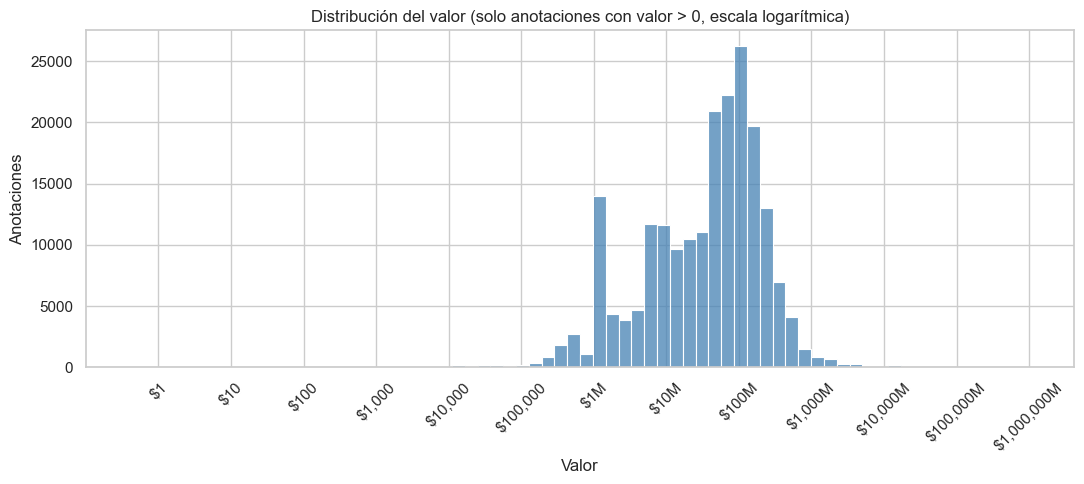

In [18]:
from matplotlib.ticker import FuncFormatter
import textwrap

def fmt_pesos(x, _=None):
    v = 10 ** x
    return f"${v/1e6:,.0f}M" if v >= 1e6 else f"${v:,.0f}"

fig, ax = plt.subplots(figsize=(11, 5))
sns.histplot(df["log_valor"].dropna(), bins=70, color="steelblue", ax=ax)
ax.xaxis.set_major_formatter(FuncFormatter(fmt_pesos))
ax.set_xticks(range(0, 13, 1))
ax.tick_params(axis="x", rotation=45)
ax.set_title("Distribución del valor (solo anotaciones con valor > 0, escala logarítmica)")
ax.set_xlabel("Valor")
ax.set_ylabel("Anotaciones")
plt.tight_layout()
plt.show()

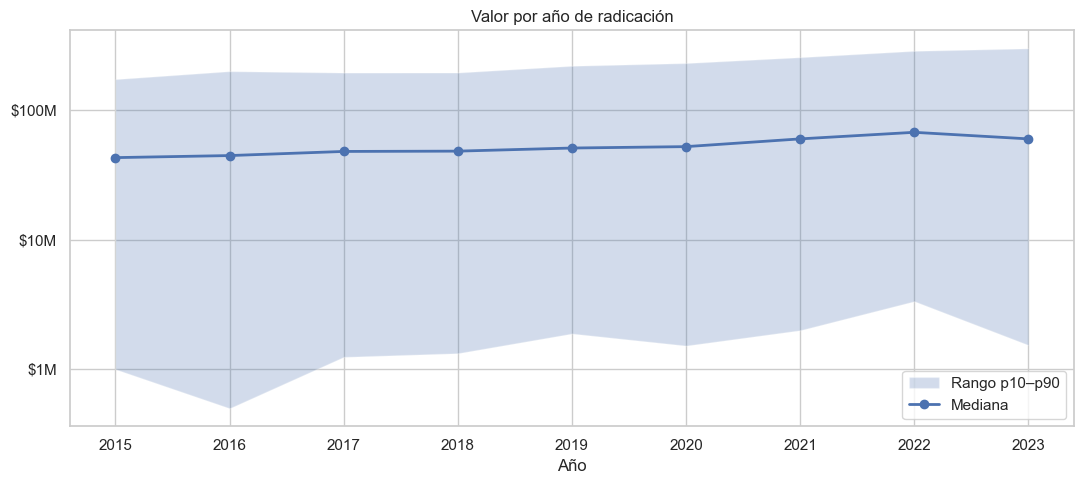

,p10,mediana,p90
year_radica,,,
2015,"1,000,000.00","43,007,500.00","173,555,008.00"
2016,"500,000.00","44,607,504.00","200,000,000.00"
2017,"1,245,000.00","48,000,000.00","195,000,000.00"
2018,"1,328,900.00","48,261,848.00","195,164,000.00"
2019,"1,886,000.00","51,000,000.00","220,000,000.00"
2020,"1,521,532.00","52,289,000.00","230,980,856.00"
2021,"2,000,000.00","60,000,000.00","256,274,189.00"
2022,"3,349,200.00","67,435,220.00","286,986,899.00"
2023,"1,538,462.00","60,000,000.00","300,000,000.00"


In [19]:
g = df.dropna(subset=["valor_pos"]).groupby("year_radica")["valor_pos"]
res = pd.DataFrame({
    "p10": g.quantile(.10), "mediana": g.median(), "p90": g.quantile(.90)
})

fig, ax = plt.subplots(figsize=(11, 5))
ax.fill_between(res.index, res["p10"], res["p90"], alpha=0.25, label="Rango p10–p90")
ax.plot(res.index, res["mediana"], marker="o", lw=2, label="Mediana")
ax.set_yscale("log")
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"${v/1e6:,.0f}M"))
ax.set_xticks(res.index)
ax.set_title("Valor por año de radicación")
ax.set_xlabel("Año")
ax.legend()
plt.tight_layout()
plt.show()
res.round(0)

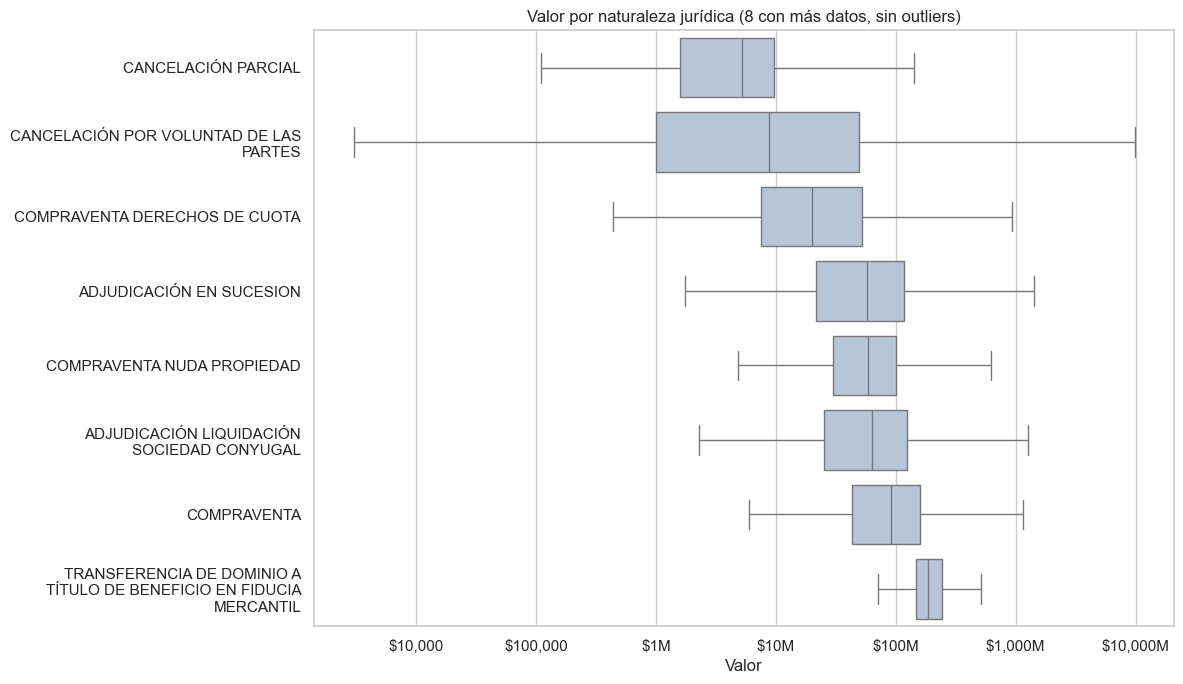

In [20]:
validos = df.dropna(subset=["valor_pos"])
top_val = validos["nombre_natujur"].value_counts().head(8).index

sub = validos[validos["nombre_natujur"].isin(top_val)].copy()
sub["natujur_corta"] = sub["nombre_natujur"].apply(lambda s: "\n".join(textwrap.wrap(s, 32)))
orden = sub.groupby("natujur_corta")["log_valor"].median().sort_values().index

fig, ax = plt.subplots(figsize=(12, 7))
sns.boxplot(data=sub, y="natujur_corta", x="log_valor", order=orden,
            showfliers=False, color="lightsteelblue", ax=ax)
ax.xaxis.set_major_formatter(FuncFormatter(fmt_pesos))
ax.set_xlabel("Valor")
ax.set_ylabel("")
ax.set_title("Valor por naturaleza jurídica (8 con más datos, sin outliers)")
plt.tight_layout()
plt.show()

In [21]:
# ¿Cuántas anotaciones comparten el mismo documento y el mismo valor?
llave = ["documento_justificativo", "valor"]
rep = (df[df["valor"] > 0]
       .groupby(llave).agg(anotaciones=("pk", "size"), folios=("matricula", "nunique"))
       .reset_index())

print("Documentos con valor:", len(rep))
print("Documentos replicados en más de 1 folio:", (rep["folios"] > 1).sum())
print("\nTop 10 documentos más replicados:")
print(rep.nlargest(10, "folios").assign(
    documento_justificativo=lambda d: d["documento_justificativo"].str[:60]
).to_string(index=False))

# Valor deduplicado por documento (una fila por documento+valor)
df_doc = df[df["valor"] > 0].drop_duplicates(subset=llave).copy()
print("\nSuma de valor ORIGINAL :", f"${df['valor'].sum():,.0f}")
print("Suma de valor DEDUPLICADO:", f"${df_doc['valor'].sum():,.0f}")

Documentos con valor: 164535
Documentos replicados en más de 1 folio: 24137

Top 10 documentos más replicados:
                                     documento_justificativo            valor  anotaciones  folios
  00-ESCRITURA 4423 DE 29/06/2016;  NOTARIA QUINTA - PEREIRA       500,000.00         1383    1201
 00-ESCRITURA 4803 DE 29/12/2015;  NOTARIA TERCERA - PEREIRA   502,756,992.00          455     455
 00-ESCRITURA 4802 DE 29/12/2015;  NOTARIA TERCERA - PEREIRA    16,058,061.00          437     437
                00-ESCRITURA 4423 DE 29/06/2016; 290-PEREIRA       500,000.00          199     199
00-ESCRITURA 2295 DE 22/07/2020;  NOTARIA VEINTIUNO - BOGOTA       628,238.00          185     185
 00-ESCRITURA 2570 DE 27/09/2018;  NOTARIA SEGUNDA - PEREIRA     1,000,000.00          176     176
                     00-ESCRITURA 1990 DEL 10/08/22; PEREIRA    10,000,000.00          150     150
  00-ESCRITURA 442 DE 26/02/2016;  NOTARIA SEGUNDA - PEREIRA 1,487,394,050.00          145     14

In [22]:
q1, q3 = df["log_valor"].quantile([.25, .75])
lim = q3 + 3 * (q3 - q1)

out = df[df["log_valor"] > lim].sort_values("valor", ascending=False)
out[["matricula", "year_radica", "nombre_natujur", "valor", "documento_justificativo"]].assign(
    nombre_natujur=lambda d: d["nombre_natujur"].str[:35],
    documento_justificativo=lambda d: d["documento_justificativo"].str[:45],
).to_string(index=False)
print(out[["matricula", "year_radica", "nombre_natujur", "valor"]].head(25).to_string(index=False))

# Valores sospechosos por bajos (menores a 1.000 pesos)
print("\nValores positivos menores a $1.000:", ((df["valor"] > 0) & (df["valor"] < 1000)).sum())

 matricula  year_radica                           nombre_natujur                valor
290-106837         2021   CANCELACIÓN POR VOLUNTAD DE LAS PARTES 1,000,000,000,000.00
290-158684         2021                              COMPRAVENTA   820,000,000,000.00
 290-61272         2019 ADJUDICACIÓN LIQUIDACIÓN DE LA COMUNIDAD   390,800,015,000.00
 290-99962         2017                              COMPRAVENTA   378,000,015,000.00
 290-99963         2017                              COMPRAVENTA   378,000,015,000.00
 290-99966         2017                              COMPRAVENTA   378,000,015,000.00
 290-99967         2017                              COMPRAVENTA   378,000,015,000.00
 290-99964         2017                              COMPRAVENTA   378,000,015,000.00
 290-99965         2017                              COMPRAVENTA   378,000,015,000.00
 290-99969         2017                              COMPRAVENTA   378,000,015,000.00
 290-99968         2017                              C

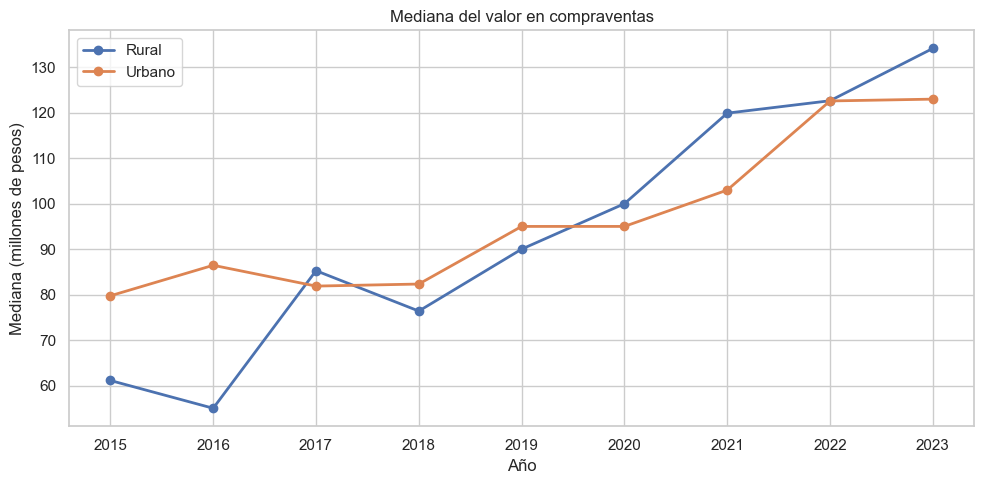

In [23]:
cv = df[(df["cod_natujur"].astype(str) == "125") & df["valor_pos"].notna()
        & (df["tipo_predio_zona"] != "SIN INFORMACION")]

med = cv.groupby(["year_radica", "tipo_predio_zona"])["valor_pos"].median().unstack()

fig, ax = plt.subplots(figsize=(10, 5))
for col in med.columns:
    ax.plot(med.index, med[col] / 1e6, marker="o", lw=2, label=col.title())
ax.set_xticks(med.index)
ax.set_ylabel("Mediana (millones de pesos)")
ax.set_xlabel("Año")
ax.set_title("Mediana del valor en compraventas")
ax.legend()
plt.tight_layout()
plt.show()

## Variables de conteo y relaciones

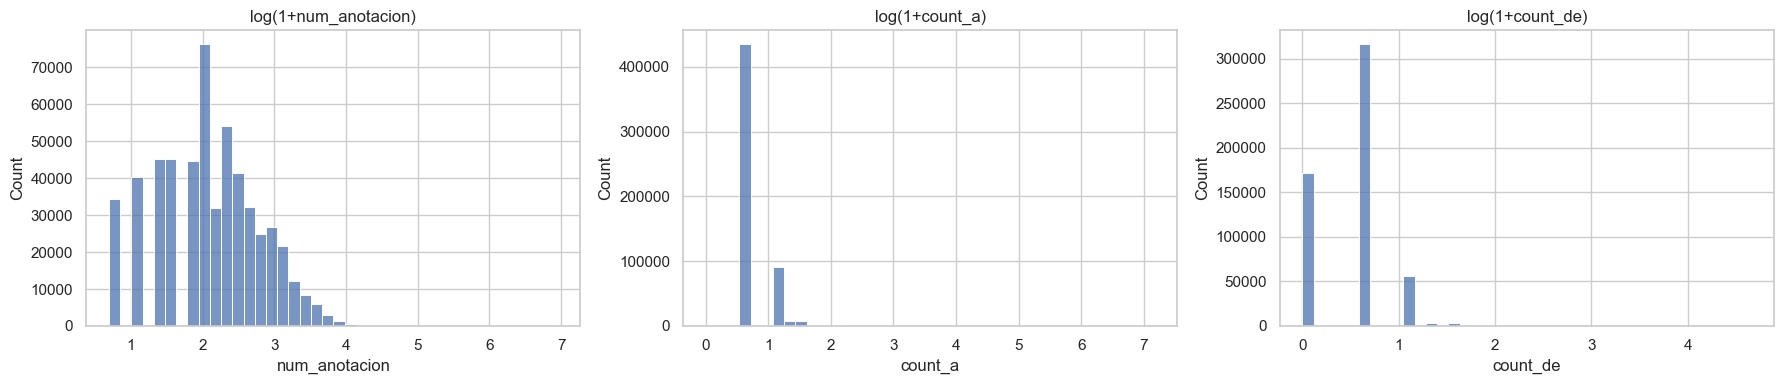

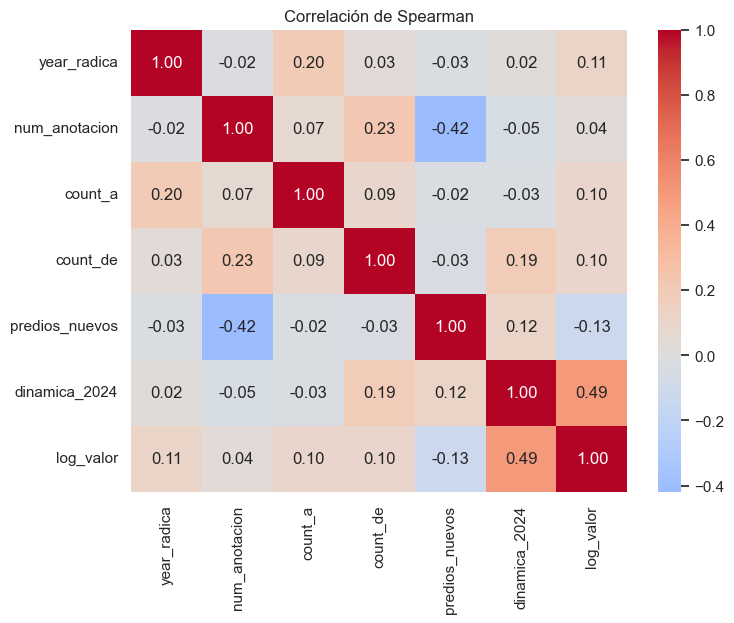

dinamica_2024       0    1
tipo_predio_zona          
RURAL            0.48 0.52
SIN INFORMACION  0.61 0.39
URBANO           0.45 0.55
              num_anotacion  count_a  count_de
estado_folio                                  
ACTIVO                10.03     1.51      0.91
CERRADO                8.88     2.51      0.44


In [16]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4))
for ax, col in zip(axes, ["num_anotacion", "count_a", "count_de"]):
    sns.histplot(np.log1p(df[col]), bins=40, ax=ax)
    ax.set_title(f"log(1+{col})")
plt.tight_layout()
plt.show()

num_cols = ["year_radica", "num_anotacion", "count_a", "count_de", "predios_nuevos",
            "dinamica_2024", "log_valor"]
plt.figure(figsize=(8, 6))
sns.heatmap(df[num_cols].corr(method="spearman"), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlación de Spearman")
plt.show()

# Tasa de dinámica por naturaleza jurídica y tipo de predio
print(pd.crosstab(df["tipo_predio_zona"], df["dinamica_2024"], normalize="index").round(3))
print(df.groupby("estado_folio")[["num_anotacion", "count_a", "count_de"]].mean().round(2))

## Nivel Folio

In [17]:
folio = df.groupby("matricula").agg(
    anotaciones=("pk", "size"),
    primer_anio=("year_radica", "min"),
    ultimo_anio=("year_radica", "max"),
    valor_total=("valor", "sum"),
    tipo_predio=("tipo_predio_zona", "first"),
    estado=("estado_folio", "first"),
)
print(folio.describe().round(2))
print(folio.nlargest(10, "anotaciones"))

       anotaciones  primer_anio  ultimo_anio          valor_total
count   142,665.00   142,665.00   142,665.00           142,665.00
mean          3.87     2,017.92     2,019.98       283,662,752.34
std           3.19         2.57         2.58     6,202,484,535.11
min           1.00     2,015.00     2,015.00                 0.00
25%           2.00     2,016.00     2,018.00         1,000,000.00
50%           3.00     2,017.00     2,021.00        64,079,000.00
75%           5.00     2,020.00     2,022.00       172,301,685.00
max         259.00     2,023.00     2,023.00 1,000,000,000,000.00
            anotaciones  primer_anio  ultimo_anio      valor_total  \
matricula                                                            
290-1501            259         2019         2023   475,426,509.00   
290-143078          197         2015         2023             0.00   
290-51338           170         2015         2023 2,301,174,558.86   
290-184060          124         2015         2023       